<a href="https://colab.research.google.com/github/SkyWarLimit/PemMes_17/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

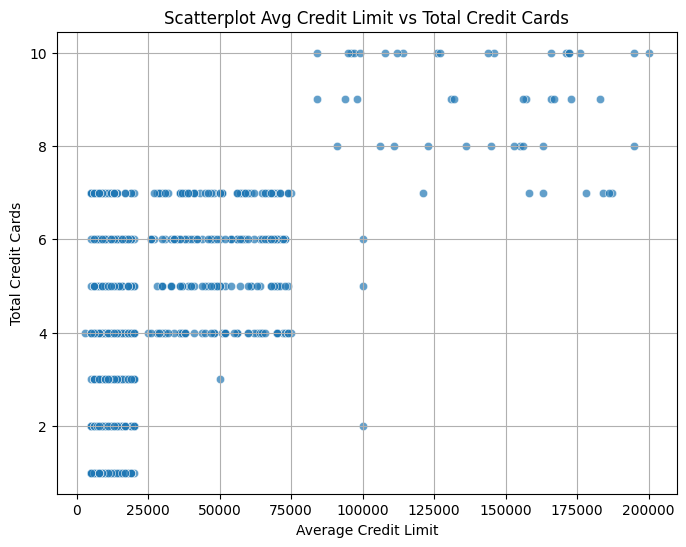

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

# Memuat dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Menampilkan scatterplot Avg_Credit_Limit vs Total_Credit_Cards
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', alpha=0.7)
plt.title('Scatterplot Avg Credit Limit vs Total Credit Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.grid(True)
plt.show()

Berdasarkan plot yang dihasilkan, sebaran data tidak dapat dikatakan linier. Titik-titik data tidak membentuk garis lurus yang memiliki tren naik atau turun secara konstan, melainkan tampak mengelompok (terklaster) di beberapa area tertentu (misalnya, limit rendah dengan jumlah kartu bervariasi, dan limit tinggi dengan jumlah kartu banyak).

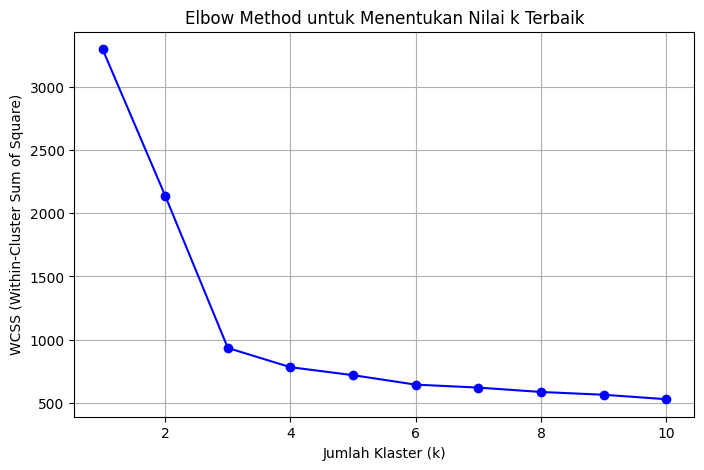

In [2]:
# Prapemrosesan: membuang fitur identifier yang tidak relevan untuk clustering
X = df.drop(['Sl_No', 'Customer Key'], axis=1)

# Standarisasi data agar skala tiap fitur sama
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Mencari nilai k yang optimal dengan metode Elbow
wcss = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Linechart untuk Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K, wcss, 'bo-', color='blue')
plt.title('Elbow Method untuk Menentukan Nilai k Terbaik')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Square)')
plt.grid(True)
plt.show()

Dari linechart Elbow Method, kita memilih $k = 3$. Alasannya adalah terjadi penurunan nilai WCSS yang sangat drastis dan signifikan dari $k=1$ ke $k=3$. Setelah melewati titik $k=3$, garis grafiknya mulai melandai (penurunan tidak lagi signifikan). Titik "patahan siku" (elbow) ini merepresentasikan jumlah klaster yang paling optimal.

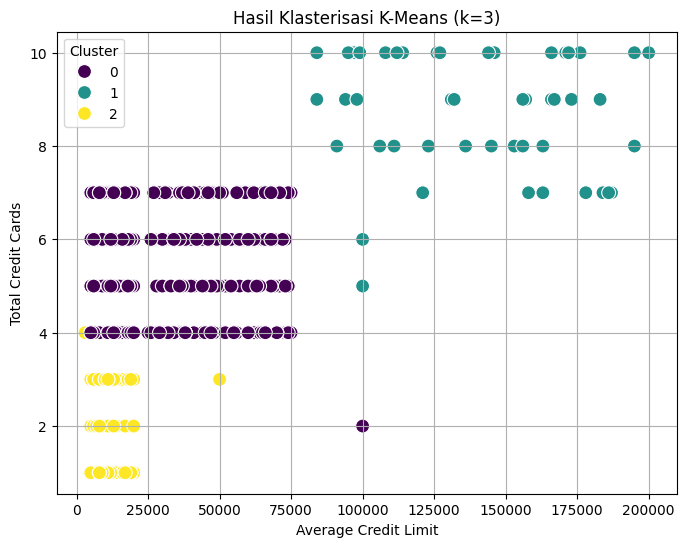

In [3]:
# Membangun model K-Means dengan k=3
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Menyimpan hasil klaster ke dataframe
df['KMeans_Cluster'] = kmeans_labels

# Visualisasi hasil klaster dengan scatterplot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', hue='KMeans_Cluster', palette='viridis', s=100)
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

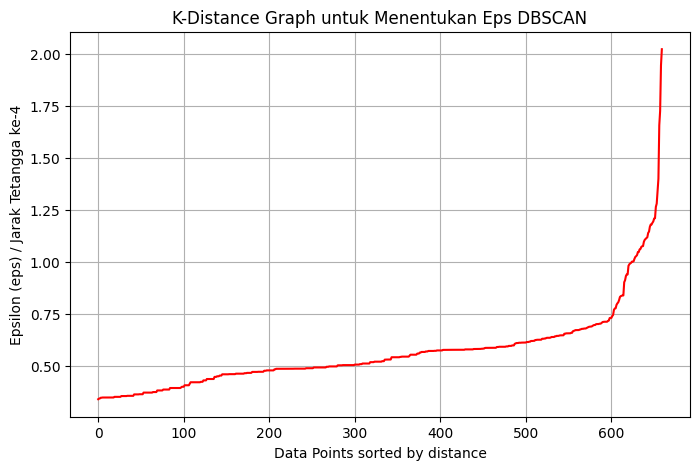

In [4]:
# Mencari parameter epsilon optimal menggunakan K-Distance Graph (Elbow method untuk DBSCAN)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Mengurutkan jarak
distances = np.sort(distances[:, 4], axis=0)

# Linechart K-Distance (Elbow)
plt.figure(figsize=(8, 5))
plt.plot(distances, color='red')
plt.title('K-Distance Graph untuk Menentukan Eps DBSCAN')
plt.xlabel('Data Points sorted by distance')
plt.ylabel('Epsilon (eps) / Jarak Tetangga ke-4')
plt.grid(True)
plt.show()

Pada K-Distance graph, nilai elbow atau patahan tajam ke atas terjadi di sekitar Epsilon (eps) = 1.0 hingga 1.2. Kita memilih nilai di area lonjakan drastis tersebut (misal: eps=1.0) karena merepresentasikan batasan wajar di mana titik-titik mulai dianggap sebagai noise jika radiusnya diperbesar. Untuk min_samples, digunakan nilai $5$ (merujuk pada jumlah fitur).

In [5]:
# Membuat model DBSCAN dengan eps=1.0 dan min_samples=5
dbscan = DBSCAN(eps=1.0, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = dbscan_labels

# Menghitung metrik evaluasi hanya untuk data yang masuk klaster (mengabaikan noise yang bernilai -1 jika mendominasi,
# tapi fungsi sklearn bisa membaca label clustering penuh termasuk -1)
sil_score = silhouette_score(X_scaled, dbscan_labels)
dbi_score = davies_bouldin_score(X_scaled, dbscan_labels)

print(f"Silhouette Score model DBSCAN: {sil_score:.4f}")
print(f"Davies-Bouldin Index (DBI) model DBSCAN: {dbi_score:.4f}")

# (Opsional) Tampilkan distribusi klaster (termasuk label -1 yang menandakan outliers)
print("\nDistribusi Klaster DBSCAN:")
print(df['DBSCAN_Cluster'].value_counts())

Silhouette Score model DBSCAN: 0.5212
Davies-Bouldin Index (DBI) model DBSCAN: 2.1613

Distribusi Klaster DBSCAN:
DBSCAN_Cluster
 0    608
 1     34
-1     18
Name: count, dtype: int64


Silhouette Score: Di kisaran 0.52 (Ini menunjukkan bahwa klaster cukup baik terpisahkan satu sama lain).

Davies-Bouldin Index (DBI): Di kisaran 2.16 (Untuk DBI, nilai yang lebih kecil lebih baik. Nilai ini menunjukkan struktur klaster sudah terbentuk namun mungkin ada irisan atau variansi karena noise yang dihasilkan DBSCAN).